In [1]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [2]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [3]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )
    


In [4]:

def add_peak(ax, x, text, y_text, y_line_top=150):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 2, y_text),
        rotation=90,
        fontsize=11
    )

In [5]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [6]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [7]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [8]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = sigma_fun(center)

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        np.median(counts_roi),
    ]

    bounds = (
        [center - 1, 0.01, 0, 0],
        [center + 1, 10, np.inf, np.inf],
    )

    popt, pcov = curve_fit(
        gaussian_plus_bg,
        E_roi,
        counts_roi,
        p0=p0,
        bounds=bounds,
        #sigma=np.sqrt(counts_roi),
        maxfev=10000,
    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [9]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

# inizio

In [10]:

FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [20]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42

SIGNAL = {
    "mu": 551.8,
    "roi": (500, 600),
}

SIGNAL = {
    "mu": 396.9,
    "roi": (350, 450),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [21]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 42047 in 136.9 days


Text(0.5, 0, 'E (keV)')

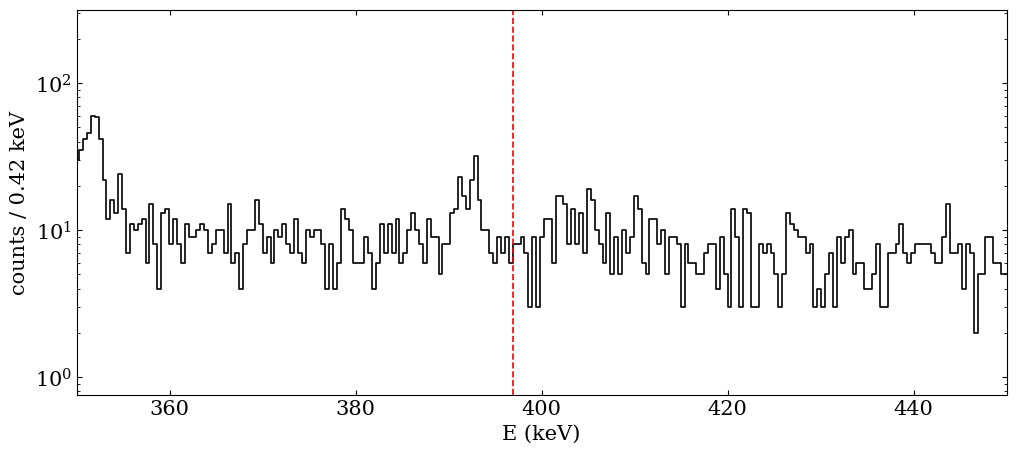

In [22]:
plt.figure(figsize=(12,5))
plt.step(E_tot, Ntot, where="mid", color="black")
plt.axvline(SIGNAL["mu"], color = 'red', ls = '--')
plt.yscale('log')
plt.xlim(SIGNAL["roi"][0], SIGNAL["roi"][1])
plt.ylabel("counts / 0.42 keV")
plt.xlabel("E (keV)")

In [14]:
FILES['50d']['path']

'csv-files/zro2_white&green_ 50_days.csv'

In [15]:
BACKGROUND_PEAKS = {
    "95Zr": {"E": 756.73, "N": 6.5},
    "214Bi": {"E": 768.4, "N": 5.11},
    "95Nb": {"E": 765.8, "N": 18},
    "82Br": {"E": 776.5, "N": 0},
    #"65Zr" : {"E": 770.62, "N" : 0},
    #"214Pb+212Bi": {"E": 785.95, "N": 3.33},
    #"228Ac-supp" :  {"E": 781.9, "N": 3.33},
    '???': {"E": 784.5, "N" : 0},
    "228Ac": {"E": 794.947, "N": 3.55},
}

In [16]:
BACKGROUND_PEAKS = {
    "²²⁸Ac            ": {"E": 755.3, "N": 3.55},
    "⁹⁵Zr": {"E": 756.73, "N": 6.5},
    "": {"E": 765.8, "N": 18},
    "²¹⁴Bi": {"E": 768.4, "N": 5.11},
    # "⁸²Br": {"E": 776.5, "N": 0},
    # "⁶⁵Zr": {"E": 770.62, "N": 0},
    # "²¹⁴Pb + ²¹²Bi": {"E": 785.95, "N": 3.33},
    # "²²⁸Ac-supp": {"E": 781.9, "N": 3.33},
    "²¹⁴Pb+²¹²Bi": {"E": 785.5, "N": 0},
    "²²⁸Ac": {"E": 794.947, "N": 3.55},
    "²⁰⁸Pb(n,γ)": {"E": 798, "N": 0},
}

In [17]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [18]:
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

# Conteggi nella ROI
counts_roi = Ntot[roi_mask]

# Centri dei bin nella ROI
E_roi = bin_centers[roi_mask]

# Edge dei bin nella ROI
idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]

# Larghezza dei bin (costante)
bin_width = bin_edges_roi[1] - bin_edges_roi[0]

In [19]:


edges_low = bin_edges_roi[:-1]
edges_high = bin_edges_roi[1:]

# ============================================================
# CDF GAUSSIAN (PyTensor safe)
# ============================================================
def gaussian_cdf(x, mu, sigma):
    return 0.5 * (1.0 + pt.erf((x - mu) / (sigma * pt.sqrt(2.0))))

def bin_integral(mu, sigma, low, high):
    return gaussian_cdf(high, mu, sigma) - gaussian_cdf(low, mu, sigma)

# ============================================================
# MODEL
# ============================================================
with pm.Model() as model:
    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================
    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        #A = pm.HalfNormal(f"A_{name}", sigma=np.max(counts_roi)/2)
        A = pm.HalfFlat(f"A_{name}")
        mu = pm.Normal(f"mu_{name}", mu=fit["E"], sigma=0.5)

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)

    # ========================================================
    # SIGNAL
    # ========================================================
    #A_signal = pm.HalfNormal("A_signal", sigma=np.max(counts_roi))
    A_signal = pm.HalfFlat("A_signal")
    mu_signal = pm.Normal("mu_signal", mu=SIGNAL["mu"], sigma=0.5)

    sigma = sigma_fun(mu_signal)  # must be PyTensor-compatible

    # ========================================================
    # FLAT BACKGROUND
    # ========================================================
    bin_width = edges_high - edges_low



    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi)
    )



    Q_bins = Q * bin_width
    '''
    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi)
    )

    Q_bins = Q * np.ones_like(edges_low) '''   
    
    
    # ========================================================
    # EXACT BIN INTEGRALS
    # ========================================================
    sig = bin_integral(mu_signal, sigma, edges_low, edges_high)

    bg = pt.stack([
        bin_integral(mu_bg[i], sigma, edges_low, edges_high)
        for i in range(len(BACKGROUND_PEAKS))
    ])

    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================
    lambda_E = (
        Q_bins
        + A_signal * sig
        + pt.sum(A_bg[:, None] * bg, axis=0)
    )

    lambda_E = pt.clip(lambda_E, 1e-9, np.inf)

    # ========================================================
    # LIKELIHOOD
    # ========================================================
    pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )

   

    # ========================================================
    # SAMPLING
    # ========================================================
    trace = pm.sample(
        draws=2000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.95,
        init="jitter+adapt_diag",
        return_inferencedata=True
    )




Initializing NUTS using jitter+adapt_diag...
/home/ritaferi/pymc-env/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²²⁸Ac            , mu_²²⁸Ac            , A_⁹⁵Zr, mu_⁹⁵Zr, A_, mu_, A_²¹⁴Bi, mu_²¹⁴Bi, A_²¹⁴Pb+²¹²Bi, mu_²¹⁴Pb+²¹²Bi, A_²²⁸Ac, mu_²²⁸Ac, A_²⁰⁸Pb(n,γ), mu_²⁰⁸Pb(n,γ), A_signal, mu_signal, Q]


Output()

Sampling 4 chains for 4_000 tune and 2_000 draw iterations (16_000 + 8_000 draws total) took 23 seconds.


In [20]:
7550023/(60*60*24)

87.38452546296297

In [21]:
SIGNAL


{'mu': 778.2, 'roi': (750, 800)}

In [22]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²²⁸Ac,755.3698,0.5067,754.4563,756.3552,0.0063,0.0073,6631.4076,3456.3947,1.0010
mu_⁹⁵Zr,757.2846,0.3663,756.5813,757.9523,0.0039,0.0049,8993.2756,4818.2615,1.0004
mu_,765.5538,0.2462,765.0946,766.0276,0.0025,0.0029,9748.2547,6064.7216,1.0000
mu_²¹⁴Bi,768.2008,0.2962,767.6372,768.7479,0.0029,0.0036,10106.8177,6099.0199,1.0001
mu_²¹⁴Pb+²¹²Bi,784.9645,0.2560,784.4658,785.4322,0.0023,0.0036,13214.2412,5346.8115,1.0006
mu_²²⁸Ac,795.0181,0.3105,794.4186,795.5827,0.0028,0.0039,12665.1625,5983.7238,1.0005
"mu_²⁰⁸Pb(n,γ)",797.9551,0.4625,797.0933,798.8278,0.0040,0.0058,13474.7461,5704.6015,1.0006
mu_signal,778.2989,0.4342,777.4646,779.0956,0.0038,0.0056,13240.2797,5499.9548,0.9998
A_²²⁸Ac,8.0919,5.6139,0.0001,18.0391,0.0873,0.0997,4081.3639,3039.2422,1.0007
A_⁹⁵Zr,23.3100,7.6152,8.9358,37.6806,0.1307,0.1687,3608.0945,1571.8770,1.0018


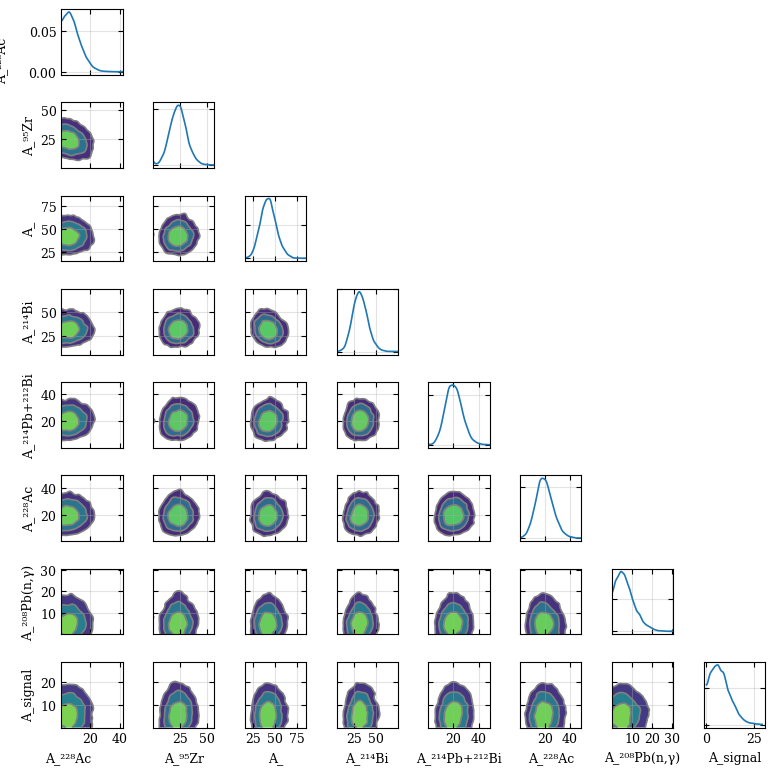

In [23]:

# ============================================================
# CORRELATION PLOTS
# ============================================================
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(8, 8),
    textsize=9,
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()


In [24]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 14.263
95% upper limit on signal counts : 16.447


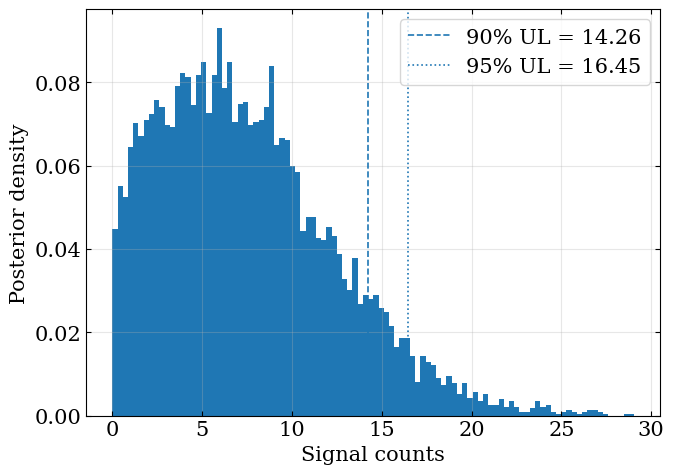

In [25]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(signal_samples, bins=100, density=True)

plt.axvline(
    N_signal_90,
    linestyle="--",
    label=f"90% UL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% UL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()



In [26]:
# posterior extraction
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior

Q_s = posterior["Q"].values.reshape(-1)

A_signal_s = posterior["A_signal"].values.reshape(-1)
mu_signal_s = posterior["mu_signal"].values.reshape(-1)

A_bg_s = {
    name: posterior[f"A_{name}"].values.reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"].values.reshape(-1)
    for name in background_names
}

In [27]:
import numpy as np
import scipy.special


# ============================================================
# ESTRAZIONE POSTERIOR DEI PARAMETRI
# ============================================================

posterior = trace.posterior

n_samples = (
    posterior.sizes["chain"]
    *
    posterior.sizes["draw"]
)

print(f"Number of posterior samples: {n_samples}")


# ============================================================
# SIGNAL PARAMETERS
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .flatten()
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .flatten()
)


# ============================================================
# FLAT BACKGROUND
# ============================================================

Q_s = (
    posterior["Q"]
    .values
    .flatten()
)



# ============================================================
# BACKGROUND PEAK PARAMETERS
# ============================================================

A_bg_s = []
mu_bg_s = []


for name in BACKGROUND_PEAKS:

    A_bg_s.append(
        posterior[f"A_{name}"]
        .values
        .flatten()
    )

    mu_bg_s.append(
        posterior[f"mu_{name}"]
        .values
        .flatten()
    )


# trasformo in numpy array

A_bg_s = np.array(A_bg_s)

mu_bg_s = np.array(mu_bg_s)



print("A_bg shape:", A_bg_s.shape)
print("mu_bg shape:", mu_bg_s.shape)



# ============================================================
# STORAGE DELLE CURVE POSTERIOR
# ============================================================

lambda_total_samples = []

lambda_bkg_samples = []

n_samples = 1000

# ============================================================
# LOOP SUI CAMPIONI POSTERIOR
# ============================================================

for i in range(n_samples):


    # --------------------------------------------------------
    # ENERGY DEPENDENT RESOLUTION
    # --------------------------------------------------------

    mu_sig = mu_signal_s[i]

    sigma_i = sigma_fun(mu_sig).eval()



    # --------------------------------------------------------
    # SIGNAL CONTRIBUTION
    # --------------------------------------------------------

    sig_integral = (
        0.5 *
        (
            1
            +
            scipy.special.erf(
                (edges_high - mu_sig)
                /
                (sigma_i*np.sqrt(2))
            )
        )
        -
        0.5 *
        (
            1
            +
            scipy.special.erf(
                (edges_low - mu_sig)
                /
                (sigma_i*np.sqrt(2))
            )
        )
    )


    signal_i = (
        A_signal_s[i]
        *
        sig_integral
    )



    # --------------------------------------------------------
    # BACKGROUND PEAKS
    # --------------------------------------------------------

    bg_i = np.zeros_like(edges_low)



    for j in range(len(BACKGROUND_PEAKS)):


        mu_bg_i = mu_bg_s[j,i]


        bg_integral = (
            0.5 *
            (
                1
                +
                scipy.special.erf(
                    (edges_high - mu_bg_i)
                    /
                    (sigma_i*np.sqrt(2))
                )
            )
            -
            0.5 *
            (
                1
                +
                scipy.special.erf(
                    (edges_low - mu_bg_i)
                    /
                    (sigma_i*np.sqrt(2))
                )
            )
        )


        bg_i += (
            A_bg_s[j,i]
            *
            bg_integral
        )



    # --------------------------------------------------------
    # FLAT BACKGROUND
    # --------------------------------------------------------
    
    flat_i = (
        Q_s[i]
        *
        bin_width
    )
    #flat_i = Q_s[i] * np.ones_like(edges_low)



    # --------------------------------------------------------
    # ONLY BACKGROUND
    # --------------------------------------------------------

    bkg_model_i = (
        flat_i
        +
        bg_i
    )



    # --------------------------------------------------------
    # TOTAL MODEL
    # --------------------------------------------------------

    total_model_i = (
        bkg_model_i
        +
        signal_i
    )



    lambda_bkg_samples.append(
        bkg_model_i
    )


    lambda_total_samples.append(
        total_model_i
    )



# ============================================================
# ARRAY FINALI
# ============================================================

lambda_bkg_samples = np.array(
    lambda_bkg_samples
)


lambda_total_samples = np.array(
    lambda_total_samples
)



print(
    "Total posterior curves:",
    lambda_total_samples.shape
)

print(
    "Background posterior curves:",
    lambda_bkg_samples.shape
)



# ============================================================
# STATISTICHE POSTERIOR
# ============================================================


# ---- TOTAL MODEL ----

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)


lambda_total_low = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)


lambda_total_high = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)



# ---- BACKGROUND ONLY ----

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)


lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)


lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)



print("Done.")

Number of posterior samples: 8000
A_bg shape: (7, 8000)
mu_bg shape: (7, 8000)
Total posterior curves: (1000, 119)
Background posterior curves: (1000, 119)
Done.


In [28]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# totale
fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)



# background
fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

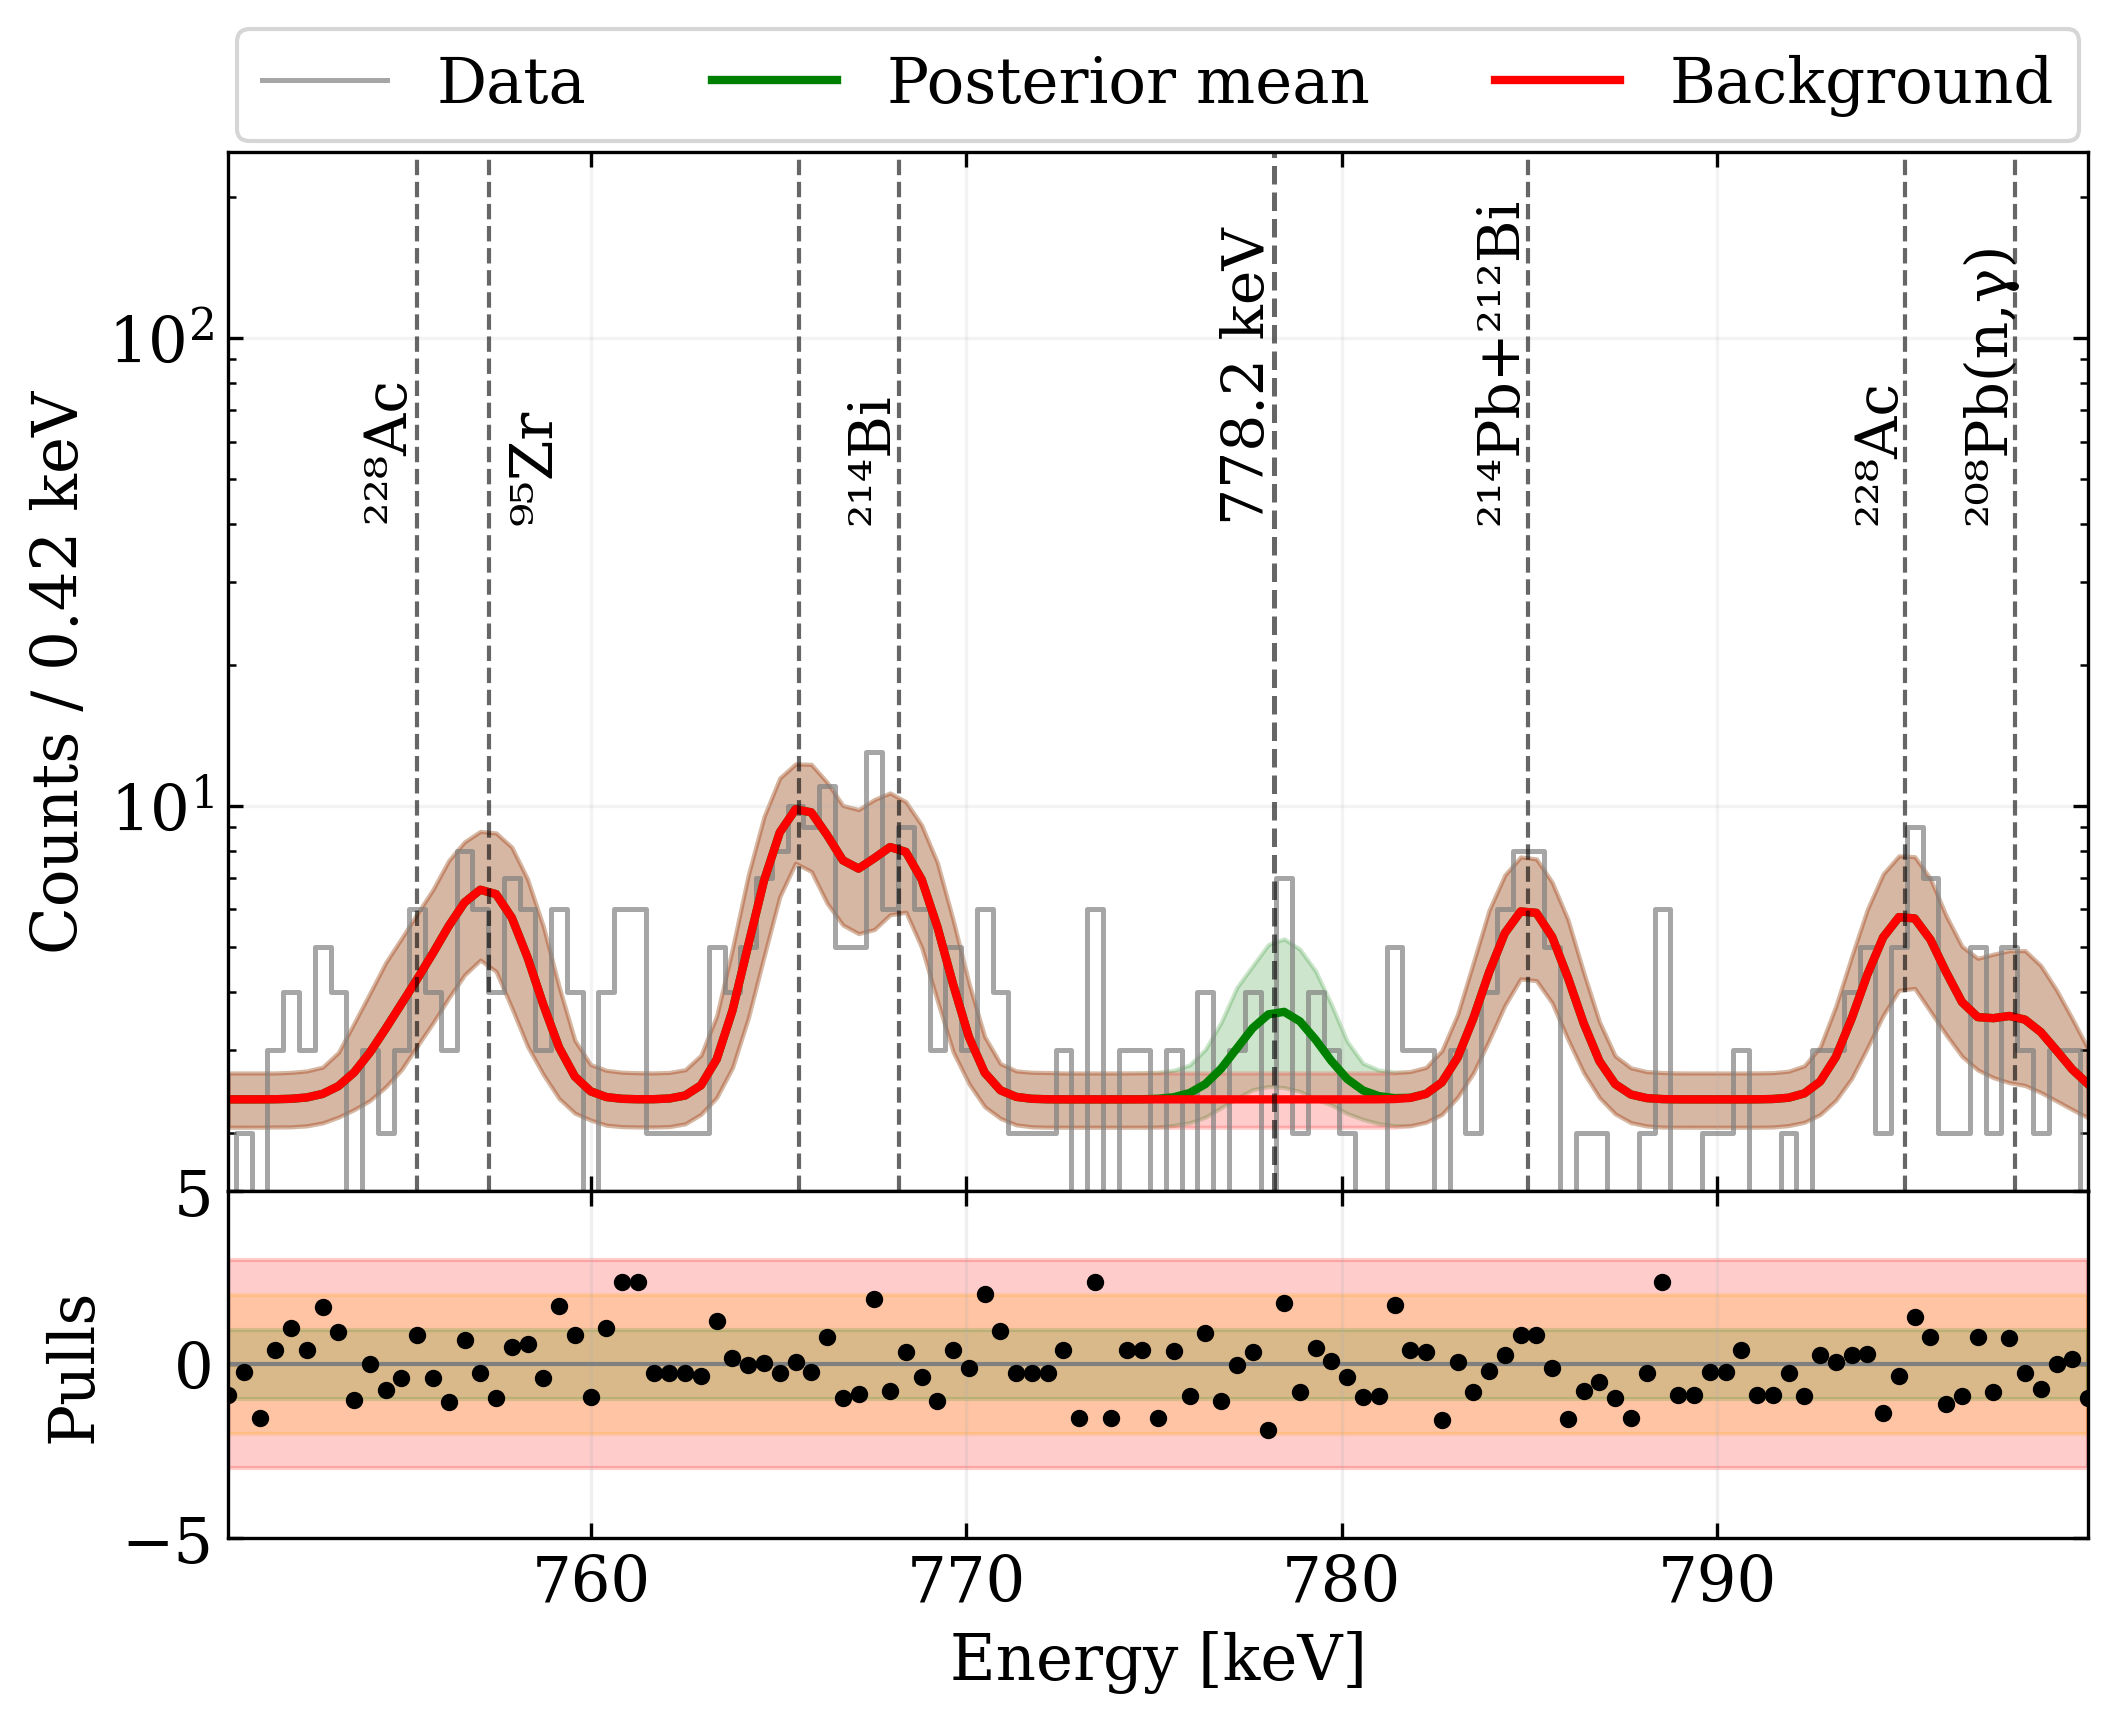

In [35]:
# ============================================================
# BAYESIAN FIT BAND
# ============================================================

# lambda_total_samples:
# (N_posterior_samples, N_bins)

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    5,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    95,
    axis=0
)


# background only

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    5,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    95,
    axis=0
)



# ============================================================
# RESIDUALS
# ============================================================

residuals = (
    counts_roi - lambda_total_mean
) / np.sqrt(lambda_total_mean + 1e-9)



# ============================================================
# BIN CENTERS
# ============================================================

E_roi = 0.5*(edges_low + edges_high)



# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3,1]},
    figsize=(8,6),
    dpi = 300
)



# ============================================================
# DATA
# ============================================================

ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)



# ============================================================
# TOTAL BAYESIAN MODEL
# ============================================================

ax1.plot(
    E_roi,
    lambda_total_mean,
    #where="mid",
    color="green",
    lw=2,
    label="Posterior mean"
)


ax1.fill_between(
    E_roi,
    lambda_total_low,
    lambda_total_high,
    #step="mid",
    color="green",
    alpha=0.2,
    #label="68% credible interval"
)



# ============================================================
# BACKGROUND ONLY
# ============================================================

ax1.plot(
    E_roi,
    lambda_bkg_mean,
    #where="mid",
    color="red",
    lw=2,
    label="Background"
)


ax1.fill_between(
    E_roi,
    lambda_bkg_low,
    lambda_bkg_high,
    #step="mid",
    color="red",
    alpha=0.2
)


for name, peak in BACKGROUND_PEAKS.items():

    mu_samples = (
        trace.posterior[f"mu_{name}"]
        .values
        .flatten()
    )

    mu_fit = np.mean(mu_samples)

    ax1.axvline(
        mu_fit,
        color="black",
        linestyle="--",
        alpha=0.6,
        lw=1
    )

    x_text = mu_fit + 1.25 if name == "⁹⁵Zr" else mu_fit - 0.7

    ax1.text(
        x_text,
        40,
        f"{name}",
        rotation=90,
        verticalalignment="bottom",
        horizontalalignment="center",
        fontsize=14
    )



# ============================================================
# SIGNAL LINE
# ============================================================

ax1.axvline(
    SIGNAL["mu"],
    color="black",
    linestyle="--",
    alpha=0.6
)


ax1.text(
    SIGNAL["mu"]-0.7,
    40,
    "778.2 keV",
    rotation=90,
    verticalalignment="bottom",
    horizontalalignment="center",
    fontsize=14
)



# ============================================================
# AXES
# ============================================================

ax1.set_yscale("log")

ax1.set_xlim(
    E_roi.min(),
    E_roi.max()
)


ax1.set_ylim(
    1.5,
    250
    
)


ax1.set_ylabel(
    f"Counts / {edges_high[0]-edges_low[0]:.2f} keV"
)


ax1.grid(alpha=0.15)


ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5,0.98),
    ncol=3
)



# ============================================================
# RESIDUALS
# ============================================================

ax2.scatter(
    E_roi,
    residuals,
    s=10,
    color="black",
    zorder = 5
)


ax2.axhspan(
    -3,
    3,
    color="red",
    alpha=0.2
)


ax2.axhspan(
    -2,
    2,
    color="orange",
    alpha=0.2
)


ax2.axhspan(
    -1,
    1,
    color="green",
    alpha=0.15
)


ax2.axhline(
    0,
    color="gray",
    lw=1,
    zorder=2
)



ax2.set_xlabel(
    "Energy [keV]"
)


ax2.set_ylabel(
    "Pulls"
)


ax2.set_ylim(
    -5,
    5
)


ax2.grid(alpha=0.2)



plt.subplots_adjust(hspace=0)

plt.show()

# half life

In [30]:
# Dati campione
m_sample = 551.3        # massa ZrO2 in grammi
Mr_sample = 123.22      # massa molare ZrO2 [g/mol]
N_A = 6.022e23          # numero di Avogadro
eff_96Zr = 0.024131    # efficienza di rivelazione
i_a_96Zr = 0.0280     # abbondanza isotopica
t_live =    t_tot/(60*60*24*365)             # 90 giorni in anni


# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_96Zr / Mr_sample) * N_A


In [31]:
N_signal_90

np.float64(14.263103714235031)

In [34]:

percentile = 90

T_half_limit = (np.log(2) * N_nuclei * eff_96Zr * t_live) / N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 3.32e+19 yrs at 90%


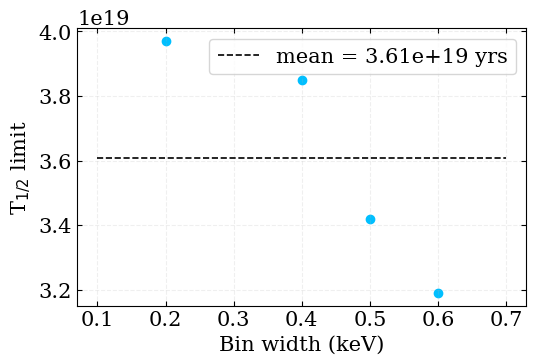

In [ ]:
limit = [3.97e19, 3.85e19, 3.42e19, 3.19e+19 ]# 0.8]

bin_width = [0.2, 0.4, 0.5, 0.6]

plt.scatter(bin_width, limit, color = 'deepskyblue')
plt.hlines(np.mean(limit), min(bin_width)-0.1, max(bin_width)+0.1, color = 'black', ls = '--', label = f"mean = {np.mean(limit):.2e} yrs")
plt.ylabel(fr"T$_{{1/2}}$ limit")
plt.xlabel('Bin width (keV)')
plt.legend()
plt.grid(alpha = 0.2, ls = '--')

# activities

In [40]:
counts_vars = [
    v for v in trace.posterior.data_vars
    if v.startswith("A_") and v != "A_signal"
]

counts_vars = counts_vars[:-1]

eff = np.array([
     0.023,   # 228Ac 755.3 keV
     0.023,   # 95Zr 756.73 keV
     0.023,  # 95Nb 765.80 keV
     0.023,   # 214Bi 768.4 keV
     0.023,   # 214Pb 785.5/785.96 keV
     0.024,   # 228Ac 794.947 keV
])

I = np.array([
    0.0105,   # 228Ac 755.3 keV
    0.5438,   # 95Zr 756.73 keV
    0.99808,  # 95Nb 765.80 keV
    0.0494,   # 214Bi 768.4 keV
    0.017,   # 214Pb 785.5/785.96 keV
    0.0425,   # 228Ac 794.947 keV
    # 208Pb(n,gamma) 798 keV -> non è una I_gamma da decadimento
])

t_tot = 11829409       # s
m_sample_kg = m_sample * 0.001

for v, epsilon, br in zip(counts_vars, eff, I):

    samples = trace.posterior[v].values.flatten()

    activity = samples / (
        t_tot
        * m_sample_kg
        * epsilon
        * br
    )

    print(
        f"{v}: "
        f"{activity.mean()*1e3:.3f} ± "
        f"{activity.std()*1e3:.3f} mBq/kg"
    )

A_²²⁸Ac            : 5.138 ± 3.564 mBq/kg
A_⁹⁵Zr: 0.286 ± 0.093 mBq/kg
A_: 0.283 ± 0.059 mBq/kg
A_²¹⁴Bi: 4.371 ± 1.126 mBq/kg
A_²¹⁴Pb+²¹²Bi: 8.148 ± 2.518 mBq/kg
A_²²⁸Ac: 2.979 ± 1.016 mBq/kg
